# 05 — RT-DETR-L

COCO-pretrained, same data and 1.5 GPU-h budget as the CNNs.

| run | change |
|---|---|
| `rtdetr-e0` | baseline, 300 queries |
| `rtdetr-e1` | 600 queries |
| `rtdetr-e2` | 600 queries + matching cost class/L1/GIoU 1.5/7.5/3.0 (was 2/5/2) + 200 denoising queries |
| `rtdetr-e3-ft` | fine-tune `rtdetr-e0` on `k=2`, cosine LR 1.5e-4, copy-paste 0.2, mixup 0.1, 2.3 GPU-h |

In [1]:
import os, sys
from pathlib import Path

if Path.cwd().name == "notebooks":          # always run from the repository root
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path("src").resolve()))  # use the local `vdet` package even without `pip install -e .`

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from vdet.paths import P
from vdet.notebook import *   # setup_notebook, results_table, show_image, *_experiment, evaluate_preds, ...

setup_notebook(seed=42)

# Training cells are resumable: a run whose checkpoint already exists in checkpoints/ is not
# trained again (its training log and metrics are loaded). Delete the checkpoint to retrain.

Project root : /home/marko/ucu-ai-hw-2
Data         : /home/marko/ucu-ai-hw-2/data (exists=True)
Cache        : /home/marko/ucu-ai-hw-2/cache (exists=True)
Checkpoints  : /home/marko/ucu-ai-hw-2/checkpoints
Device       : NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
from vdet.config import write_model_yaml

AUG = dict(hflip=0.5, vflip=0.0, degrees=0.0, scale_min=0.5, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3)
INF = dict(conf_thresh=0.001, nms_iou=0.6, max_det=500, slim_conf_thresh=0.05)

# RT-DETR-L architecture with 600 decoder queries (last argument of RTDETRDecoder)
RTDETR_L_NQ600_YAML = """
nc: 8
scales:
  l: [1.00, 1.00, 1024]
backbone:
  - [-1, 1, HGStem, [32, 48]] # 0-P2/4
  - [-1, 6, HGBlock, [48, 128, 3]] # stage 1
  - [-1, 1, DWConv, [128, 3, 2, 1, False]] # 2-P3/8
  - [-1, 6, HGBlock, [96, 512, 3]] # stage 2
  - [-1, 1, DWConv, [512, 3, 2, 1, False]] # 4-P4/16
  - [-1, 6, HGBlock, [192, 1024, 5, True, False]]
  - [-1, 6, HGBlock, [192, 1024, 5, True, True]]
  - [-1, 6, HGBlock, [192, 1024, 5, True, True]] # stage 3
  - [-1, 1, DWConv, [1024, 3, 2, 1, False]] # 8-P5/32
  - [-1, 6, HGBlock, [384, 2048, 5, True, False]] # stage 4
head:
  - [-1, 1, Conv, [256, 1, 1, None, 1, 1, False]] # 10 input_proj.2
  - [-1, 1, AIFI, [1024, 8]]
  - [-1, 1, Conv, [256, 1, 1]] # 12, Y5, lateral_convs.0
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [7, 1, Conv, [256, 1, 1, None, 1, 1, False]] # 14 input_proj.1
  - [[-2, -1], 1, Concat, [1]]
  - [-1, 3, RepC3, [256]] # 16, fpn_blocks.0
  - [-1, 1, Conv, [256, 1, 1]] # 17, Y4, lateral_convs.1
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [3, 1, Conv, [256, 1, 1, None, 1, 1, False]] # 19 input_proj.0
  - [[-2, -1], 1, Concat, [1]] # cat backbone P4
  - [-1, 3, RepC3, [256]] # X3 (21), fpn_blocks.1
  - [-1, 1, Conv, [256, 3, 2]] # 22, downsample_convs.0
  - [[-1, 17], 1, Concat, [1]] # cat Y4
  - [-1, 3, RepC3, [256]] # F4 (24), pan_blocks.0
  - [-1, 1, Conv, [256, 3, 2]] # 25, downsample_convs.1
  - [[-1, 12], 1, Concat, [1]] # cat Y5
  - [-1, 3, RepC3, [256]] # F5 (27), pan_blocks.1
  - [[21, 24, 27], 1, RTDETRDecoder, [nc, 256, 600]]
"""
NQ600 = str(write_model_yaml("rtdetr-l-nq600.yaml", RTDETR_L_NQ600_YAML))

In [3]:
RTDETR_BASE = dict(family="rtdetr", seed=42, cache="k5_drop_L1920", k=5, imgsz=1280, batch=2,
                   epochs=20, time_budget_h=1.5, close_mosaic=2, workers=4, augmentation=AUG, inference=INF)
RTDETR_E0 = dict(RTDETR_BASE, run_id="rtdetr-e0", exp="e0", parent_run="", model="rtdetr-l.pt",
    hypothesis="COCO-pretrained RT-DETR-L baseline (300 queries, imgsz=1280, AdamW, 1.5 GPU-h budget) removes heuristic NMS via bipartite Hungarian matching.")
RTDETR_E1 = dict(RTDETR_BASE, run_id="rtdetr-e1", exp="e1", parent_run="rtdetr-e0", model=NQ600, pretrained_weights="rtdetr-l.pt",
    hypothesis="Increasing decoder object queries from nq=300 to nq=600 relieves top-k query bottleneck in dense aerial scenes (up to 180 objects/frame) and improves AR@500 and AP.")
RTDETR_E2 = dict(RTDETR_BASE, run_id="rtdetr-e2", exp="e2", parent_run="rtdetr-e1", model=NQ600, pretrained_weights="rtdetr-l.pt",
    rtdetr_cost_gain={"class": 1.5, "bbox": 7.5, "giou": 3.0}, rtdetr_num_denoising=200,
    hypothesis="Re-weighting Hungarian matching toward localization (bbox=7.5, giou=3.0, class=1.5 vs 5/2/2) and doubling denoising groups (100 -> 200) accelerates convergence on small aerial objects.")

train_ultralytics_run(RTDETR_E0, predict_test=True)
train_ultralytics_run(RTDETR_E1, predict_test=True)
train_ultralytics_run(RTDETR_E2, predict_test=True)

[rtdetr-e0] training completed earlier (rtdetr-e0_best.pt); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.61190,0.00028,1.74585,1.06613,0.45982,0.23905,0.46329,0.0
1,2,1.18872,0.00056,1.18963,0.63220,0.48202,0.25980,0.48610,0.0
2,3,1.51838,0.00028,1.13608,0.59669,0.47128,0.26679,0.50791,0.0


[rtdetr-e0] submission /home/marko/ucu-ai-hw-2/submissions/rtdetr-e0.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1143231, 'mean_dets_per_frame': 299.98}
[rtdetr-e0] AP=0.2654 | AP50=0.5129 | APs=0.1370 | AR500=0.4329 | epochs=3 | gpu_h=1.5184 | fps=9.04
[rtdetr-e1] training completed earlier (rtdetr-e1_best.pt); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.65600,0.00028,1.69832,0.87107,0.68492,0.24716,0.46576,0.0
1,2,1.53062,0.00041,1.17491,0.59515,0.51198,0.26419,0.50287,0.0


[rtdetr-e1] submission /home/marko/ucu-ai-hw-2/submissions/rtdetr-e1.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1905500, 'mean_dets_per_frame': 500.0}
[rtdetr-e1] AP=0.2606 | AP50=0.5012 | APs=0.1307 | AR500=0.5006 | epochs=2 | gpu_h=1.5306 | fps=8.82
[rtdetr-e2] training completed earlier (rtdetr-e2_best.pt); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,1.29706,0.00028,1.68875,0.84167,0.70974,0.24108,0.45035,0.0
1,2,1.53601,0.00042,1.22812,0.59425,0.56421,0.24703,0.47394,0.0


[rtdetr-e2] submission /home/marko/ucu-ai-hw-2/submissions/rtdetr-e2.csv: {'valid': True, 'rows': 3811, 'non_empty_rows': 3811, 'total_detections': 1905500, 'mean_dets_per_frame': 500.0}
[rtdetr-e2] AP=0.2522 | AP50=0.4851 | APs=0.1406 | AR500=0.5109 | epochs=2 | gpu_h=1.536 | fps=8.74


{'run_id': 'rtdetr-e2',
 'unit': 'F4',
 'family': 'rtdetr',
 'exp': 'e2',
 'parent_run': 'rtdetr-e1',
 'hypothesis': 'Re-weighting Hungarian bipartite matching toward spatial localization (bbox=7.5, giou=3.0, class=1.5 vs 5/2/2) and doubling denoising groups (100 -> 200) accelerates convergence on small aerial objects.',
 'cache': 'k5_drop_L1920',
 'imgsz': 1280,
 'k': 5,
 'epochs_done': 2,
 'gpu_h': 1.536,
 'gpu_type': 'NVIDIA GeForce RTX 4050 Laptop GPU',
 'AP': 0.252221,
 'AP50': 0.485145,
 'AP75': 0.230553,
 'APs': 0.140614,
 'APm': 0.230058,
 'APl': 0.417211,
 'AR500': 0.510883,
 'fps': 8.74,
 'ap_person': 0.298835,
 'ap_bicycle': 0.271776,
 'ap_car': 0.41139,
 'ap_van': 0.251134,
 'ap_truck': 0.206335,
 'ap_tricycle': 0.234875,
 'ap_bus': 0.203237,
 'ap_motor': 0.140189,
 'checkpoint_uri': '/home/marko/ucu-ai-hw-2/checkpoints/rtdetr-e2_best.pt',
 'commit': 'c19c770',
 'date': '2026-11-05'}

## Fine-tuning on denser frames

In [4]:
RTDETR_E3_FT = dict(RTDETR_BASE, run_id="rtdetr-e3-ft", exp="e3_ft", parent_run="rtdetr-e0",
    hypothesis="Fine-tuning rtdetr-e0_best.pt on 2.5x denser video frames (k=2) with cosine annealing (lr0=1.5e-4) and copy-paste augmentation unlocks full query convergence.",
    cache="k2_drop_L1920", k=2, model=str(P.ckpt / "rtdetr-e0_best.pt"), epochs=10, time_budget_h=2.3,
    lr0=0.00015, lrf=0.05, cos_lr=True, warmup_epochs=0.5,
    augmentation=dict(AUG, scale_min=0.55, copy_paste=0.20, mixup=0.10))
train_ultralytics_run(RTDETR_E3_FT)

[rtdetr-e3-ft] training completed earlier (rtdetr-e3-ft_best.pt); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,1.63904,0.00083,1.28283,0.72655,0.45805,0.24184,0.48425,0.0
1,2,2.32271,0.00044,1.09255,0.57153,0.45799,0.26212,0.51085,0.0


[rtdetr-e3-ft] AP=0.2596 | AP50=0.5077 | APs=0.1264 | AR500=0.4200 | epochs=2 | gpu_h=2.3227 | fps=9.88


{'run_id': 'rtdetr-e3-ft',
 'unit': 'U4.7',
 'family': 'rtdetr',
 'exp': 'e3_ft',
 'parent_run': 'rtdetr-e0',
 'hypothesis': 'Fine-tuning rtdetr-e0_best.pt (AP=0.2654 @ 3 ep) on 2.5x denser video frames (k=2) with cosine annealing (lr0=1.5e-4) and copy-paste augmentation unlocks full query convergence.',
 'cache': 'k2_drop_L1920',
 'imgsz': 1280,
 'k': 2,
 'epochs_done': 2,
 'gpu_h': 2.3227,
 'gpu_type': 'NVIDIA GeForce RTX 4050 Laptop GPU',
 'AP': 0.259578,
 'AP50': 0.507736,
 'AP75': 0.232043,
 'APs': 0.126388,
 'APm': 0.234976,
 'APl': 0.445151,
 'AR500': 0.420048,
 'fps': 9.88,
 'ap_person': 0.28823,
 'ap_bicycle': 0.251737,
 'ap_car': 0.442221,
 'ap_van': 0.28798,
 'ap_truck': 0.258434,
 'ap_tricycle': 0.254465,
 'ap_bus': 0.16254,
 'ap_motor': 0.13102,
 'checkpoint_uri': '/home/marko/ucu-ai-hw-2/checkpoints/rtdetr-e3-ft_best.pt',
 'commit': '4b435bd',
 'date': '2026-11-05'}

## Results and convergence vs YOLO (same budget)

,run_id,family,exp,imgsz,epochs_done,gpu_h,AP,AP50,AP75,APs,APm,APl,AR500,fps
0,rtdetr-e0,rtdetr,e0,1280,3,1.5184,0.265358,0.512870,0.240025,0.136953,0.237824,0.443852,0.432885,9.04
1,rtdetr-e1,rtdetr,e1,1280,2,1.5306,0.260605,0.501248,0.239265,0.130707,0.234131,0.441807,0.500589,8.82
2,rtdetr-e2,rtdetr,e2,1280,2,1.5360,0.252221,0.485145,0.230553,0.140614,0.230058,0.417211,0.510883,8.74
3,rtdetr-e3-ft,rtdetr,e3_ft,1280,2,2.3227,0.259578,0.507736,0.232043,0.126388,0.234976,0.445151,0.420048,9.88
4,yolo-e0,yolo,e0,1280,15,1.5038,0.206703,0.415641,0.178470,0.108474,0.208017,0.310286,0.329077,55.73
5,yolo-e1,yolo,e1,1600,11,1.5039,0.218362,0.434640,0.190284,0.131214,0.206755,0.346511,0.371609,32.52


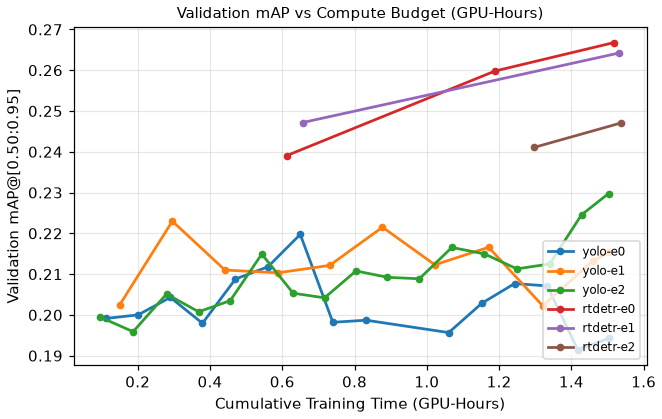

yolo-e0


,epoch,gpu_time_h,val_AP,val_AP50
0,1,0.11215,0.19913,0.40701
1,2,0.20126,0.20001,0.41042
2,3,0.29013,0.20429,0.41640
3,4,0.37913,0.19795,0.40385
4,5,0.47043,0.20879,0.41814
5,6,0.56041,0.21181,0.42203
6,7,0.64974,0.21974,0.44444
7,8,0.73994,0.19818,0.39993
8,9,0.83184,0.19870,0.40585
9,10,1.06059,0.19566,0.39477


rtdetr-e0


,epoch,gpu_time_h,val_AP,val_AP50
0,1,0.61190,0.23905,0.46329
1,2,1.18872,0.25980,0.48610
2,3,1.51838,0.26679,0.50791


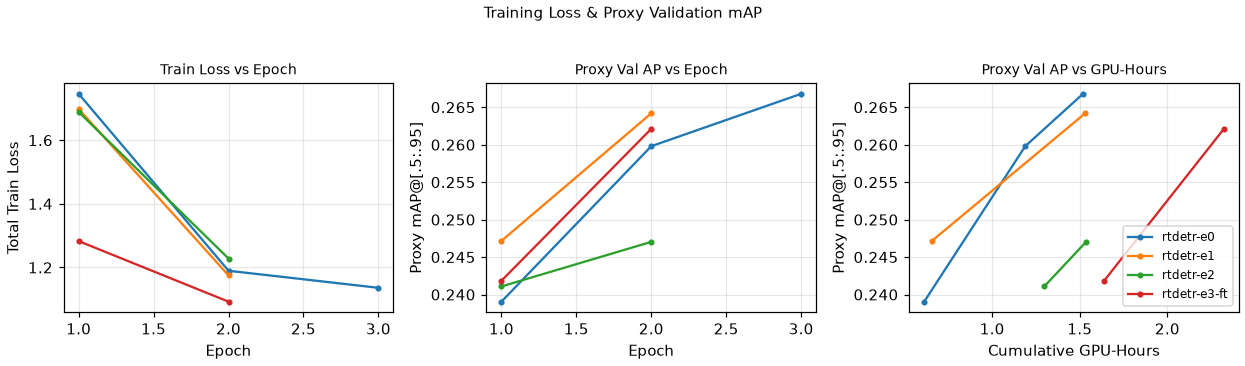

In [5]:
display(results_table(run_ids=["rtdetr-e0", "rtdetr-e1", "rtdetr-e2", "rtdetr-e3-ft", "yolo-e0", "yolo-e1"]))

from vdet.tracking.plots import map_vs_gpu_time
curves = {rid: pd.read_csv(P.exp_runs_dir / rid / "metrics.csv")
          for rid in ["yolo-e0", "yolo-e1", "yolo-e2", "rtdetr-e0", "rtdetr-e1", "rtdetr-e2"]
          if (P.exp_runs_dir / rid / "metrics.csv").exists()}
if not (P.images / "map_vs_gpu_time_all.png").exists():
    map_vs_gpu_time(curves, P.images / "map_vs_gpu_time_all.png")
show_image("map_vs_gpu_time_all.png", 750)
for rid in ["yolo-e0", "rtdetr-e0"]:
    print(rid); display(curves[rid][["epoch", "gpu_time_h", "val_AP", "val_AP50"]])
show_image("curves_rtdetr.png", 850)

## AP by objects per frame (val)

In [6]:
from vdet.data.manifest import load_manifest
from vdet.eval.coco_eval import evaluate

val_m = load_manifest().query("split == 'val'")
bins, labels = [0, 20, 40, 70, 1000], ["<20", "20-39", "40-69", "70+"]
val_m = val_m.assign(density=pd.cut(val_m["n_boxes"], bins=bins, labels=labels, right=False))
print(val_m["density"].value_counts().reindex(labels).rename("frames").to_dict())

rows = []
for rid in ["yolo-e0", "yolo-e1", "rtdetr-e0", "rtdetr-e1", "rtdetr-e2"]:
    preds = pd.read_parquet(P.runs / rid / "preds_val.parquet")
    row = {"run_id": rid}
    for lab in labels:
        keys = val_m.loc[val_m["density"] == lab, "image_key"].tolist()
        m = evaluate(preds[preds["image_key"].isin(keys)], split="val", subset=keys)
        row[f"AP {lab}"], row[f"AR500 {lab}"] = m["AP"], m["AR500"]
    rows.append(row)
density_tbl = pd.DataFrame(rows).set_index("run_id").round(4)
display(density_tbl)

{'<20': 977, '20-39': 656, '40-69': 843, '70+': 370}


,AP <20,AR500 <20,AP 20-39,AR500 20-39,AP 40-69,AR500 40-69,AP 70+,AR500 70+
run_id,,,,,,,,
yolo-e0,0.0615,0.0951,0.2685,0.4124,0.2027,0.3766,0.3001,0.4384
yolo-e1,0.1022,0.1860,0.2395,0.4232,0.2567,0.3910,0.2925,0.4453
rtdetr-e0,0.1687,0.3185,0.2923,0.4976,0.3036,0.4544,0.3419,0.4834
rtdetr-e1,0.1549,0.2490,0.3027,0.5615,0.2981,0.5211,0.3380,0.5103
rtdetr-e2,0.1132,0.3236,0.3122,0.5826,0.2797,0.4663,0.3265,0.4942


**Notes.** RT-DETR is best in every density bucket. 600 queries raise AR500 in frames with ≥ 20 objects, not AP. All 977 frames with < 20 objects come from one 4K highway clip (`uav0000268_05773_v`).

**Convergence.** 2–3 epochs fit in 1.5 GPU-h; proxy val mAP rises every epoch in all three runs (not converged). Epoch 1 of `rtdetr-e0` (0.239) already exceeds the final value of `yolo-e0` (0.194).